<a href="https://colab.research.google.com/github/Lyra0710/Multimodal-Deep-Learning-for-Reliable-GRACE-Water-Storage-Trends/blob/convlstm/notebooks/ConvLSTM_GRACE_Forecasting_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ConvLSTM for GRACE Water-Storage Forecasting

This notebook forecasts next-month terrestrial water-storage anomaly (TWSA) from 12 prior monthly maps. It runs two comparable experiments: GRACE-only (`tws`) and multimodal (`tws`, `precip`, `t2m`). It uses chronological splits and the leakage-safe `training_mask`; it does not regenerate NASA source data.

## 1. Environment and GPU Setup

Run this notebook in a Colab GPU runtime when possible. A CPU fallback is permitted for smoke tests only; full training is intentionally stopped unless a GPU is available.

In [3]:
%pip install netCDF4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 42.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 53.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [netCDF4]


In [4]:
import hashlib
import importlib.util
import json
import math
import random
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
import xarray as xr

if importlib.util.find_spec('netCDF4') is None:
    raise ImportError('This notebook needs the netCDF4 backend. Run `!pip install netCDF4` once, then restart the runtime.')

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type != 'cuda':
    print('CPU fallback is available for smoke tests. Select Runtime > Change runtime type > GPU before training.')

PyTorch: 2.14.1+cu130
CUDA available: True
Device: cuda


## 2. Google Drive Access and Output Verification

The UI hierarchy is verified here after mounting rather than assumed as a filesystem path. Final artifacts are never silently redirected to My Drive or `/content`. Colab itself cannot reliably save this `.ipynb` automatically; use **File → Save a copy in Drive** or move the notebook in the Drive UI to the verified ConvLSTM folder.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

shared_root = Path('/content/drive/Shareddrives')
output_relative = Path('DATA 255 Group/255 Group/Group Project/Final/ConvLSTM')
OUTPUT_DIR = shared_root / output_relative
if not OUTPUT_DIR.is_dir():
    raise FileNotFoundError(f'Shared Drive output folder is unavailable: {OUTPUT_DIR}. Check Drive membership and the folder hierarchy.')
probe = OUTPUT_DIR / '.colab_write_probe.txt'
try:
    probe.write_text('write access verified\n')
    probe.unlink()
except OSError as error:
    raise PermissionError(f'Cannot write to {OUTPUT_DIR}: {error}') from error

ARTIFACT_DIRS = {name: OUTPUT_DIR / name for name in ('checkpoints', 'predictions', 'metrics', 'figures', 'logs', 'configs')}
for directory in ARTIFACT_DIRS.values():
    directory.mkdir(exist_ok=True)
print(f'Verified OUTPUT_DIR: {OUTPUT_DIR}')

Mounted at /content/drive
Verified OUTPUT_DIR: /content/drive/Shareddrives/DATA 255 Group/255 Group/Group Project/Final/ConvLSTM


## 3. Configuration

Set `DATASET_PATH` to the actual mounted Shared Drive location of the verified final aligned NetCDF. Do not substitute an older dataset without `training_mask`. The default patch size is 32×32: a batch of four 12-month, three-channel float32 patches is about 0.6 MB before activations, which is practical for a Colab GPU.

In [15]:
# Set this after locating the uploaded final shared dataset. This is intentionally not guessed.
DATASET_PATH =  OUTPUT_DIR.parent / "p_t_tws_aligned_0.5deg_final.nc"
if DATASET_PATH is None:
    raise ValueError('Set DATASET_PATH to the verified aligned NetCDF before continuing.')
DATASET_PATH = Path(DATASET_PATH)
if not DATASET_PATH.is_file():
    raise FileNotFoundError(DATASET_PATH)

SEED = 42
HISTORY_MONTHS = 12
PATCH_SIZE = 32
PATCH_STRIDE = 32
BATCH_SIZE = 4
HIDDEN_CHANNELS = 16
LEARNING_RATE = 1e-3
MAX_EPOCHS = 40
PATIENCE = 8
RUN_TRAINING = True
RUN_SHORT_TRAINING_TEST = False
SHORT_TEST_EPOCHS = 2
SPLITS = {'train': ('2019-01-01', '2022-12-31'), 'validation': ('2023-01-01', '2023-12-31'), 'test': ('2024-01-01', '2025-12-31')}

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

## 4. Load and Inspect Shared Dataset

This verifies dimensions, coordinates, units, missingness, and both static masks before any model tensor is created. Xarray opens the NetCDF directly; values are not scientifically altered.

In [7]:
required = {'tws', 'precip', 't2m', 'mask', 'training_mask'}
with xr.open_dataset(DATASET_PATH, engine='netcdf4') as opened:
    missing = required - set(opened.data_vars)
    if missing: raise ValueError(f'Dataset lacks required variables: {sorted(missing)}')
    ds = opened.load()

times = pd.DatetimeIndex(ds.time.values)
expected_months = pd.date_range(times[0], times[-1], freq='MS')
if not times.equals(expected_months): raise ValueError('Dataset timestamps are not consecutive calendar months.')
DATASET_SHA256 = hashlib.file_digest(DATASET_PATH.open('rb'), 'sha256').hexdigest()
print('Dimensions:', dict(ds.sizes))
print('Variables:', list(ds.data_vars))
print('Time coverage:', times[0].date(), 'to', times[-1].date(), f'({len(times)} months)')
print('Dataset SHA-256:', DATASET_SHA256)
print('Latitude / longitude:', (float(ds.lat.min()), float(ds.lat.max())), (float(ds.lon.min()), float(ds.lon.max())))
print('Units:', {name: ds[name].attrs.get('units') for name in ('tws', 'precip', 't2m')})
print('Eligible cells:', {'mask': int(ds.mask.sum()), 'training_mask': int(ds.training_mask.sum())})
print('training_mask note:', ds.attrs.get('training_mask_note', 'missing attribute'))
for name in ('tws', 'precip', 't2m'):
    finite = ds[name].notnull().sum(('lat', 'lon'))
    missing_months = times[finite.values == 0]
    partial = int(((finite > 0) & (finite < ds.sizes['lat'] * ds.sizes['lon'])).sum())
    print(f'{name}: all-missing months={len(missing_months)}, partial-map months={partial}')

Dimensions: {'time': 304, 'lat': 240, 'lon': 720}
Variables: ['tws', 'precip', 't2m', 'mask', 'precip_anom', 't2m_anom', 'tws_anom', 'training_mask']
Time coverage: 2000-06-01 to 2025-09-01 (304 months)
Dataset SHA-256: b361f2066e8d7aee1cb1d6ae5fa640c75e44be4a2efe4a28d5652dbf28060e83
Latitude / longitude: (-59.75, 59.75) (-179.75, 179.75)
Units: {'tws': 'cm', 'precip': 'mm/month', 't2m': 'degC'}
Eligible cells: {'mask': 46325, 'training_mask': 46325}
training_mask note: Training-only availability mask using 2019-01–2022-12; use this static mask for leakage-free model cell selection.
tws: all-missing months=56, partial-map months=0
precip: all-missing months=0, partial-map months=0
t2m: all-missing months=0, partial-map months=0


## 5. Prepare Temporal and Spatial Inputs

The 12 maps immediately before each target month form its history. Samples with an incomplete history at any `training_mask` cell are skipped. NaNs are replaced with zero only after a validity mask is constructed; invalid target cells never contribute to loss or metrics. Statistics use only 2019–2022 months and `training_mask` cells.

In [8]:
def target_indices(start, end, features, target, spatial_mask):
    indices, eligible = [], spatial_mask.ravel()
    for i, date in enumerate(times):
        if date < pd.Timestamp(start) or date > pd.Timestamp(end) or i < HISTORY_MONTHS: continue
        history = features[i - HISTORY_MONTHS:i].reshape(HISTORY_MONTHS, features.shape[1], -1)[..., eligible]
        if np.isfinite(history).all() and np.isfinite(target[i].ravel()[eligible]).any(): indices.append(i)
    return np.asarray(indices, dtype=int)

def patch_origins(spatial_mask, excluded=None):
    allowed = spatial_mask.copy(); height, width = allowed.shape
    if PATCH_SIZE > height or PATCH_SIZE > width: raise ValueError('PATCH_SIZE exceeds map dimensions.')
    rows, cols = list(range(0, height - PATCH_SIZE + 1, PATCH_STRIDE)), list(range(0, width - PATCH_SIZE + 1, PATCH_STRIDE))
    if rows[-1] != height - PATCH_SIZE: rows.append(height - PATCH_SIZE)
    if cols[-1] != width - PATCH_SIZE: cols.append(width - PATCH_SIZE)
    origins = [(top, left) for top in rows
               for left in cols
               if allowed[top:top + PATCH_SIZE, left:left + PATCH_SIZE].any() and (excluded is None or not excluded[top:top + PATCH_SIZE, left:left + PATCH_SIZE].any())]
    if not origins: raise ValueError('No eligible patches were found.')
    return origins

def normalize(features, train_month_indices, spatial_mask):
    values = features[train_month_indices].reshape(len(train_month_indices), features.shape[1], -1)[..., spatial_mask.ravel()]
    mean, std = np.nanmean(values, axis=(0, 2)), np.nanstd(values, axis=(0, 2))
    if not np.isfinite(mean).all() or np.any(std == 0): raise ValueError('Invalid training-only normalization statistics.')
    return (features - mean[None, :, None, None]) / std[None, :, None, None], mean, std

training_mask = ds.training_mask.values.astype(bool)
all_features = np.stack([ds.tws.values, ds.precip.values, ds.t2m.values], axis=1).astype(np.float32)
target_tws = ds.tws.values.astype(np.float32)
train_month_indices = np.flatnonzero((times >= SPLITS['train'][0]) & (times <= SPLITS['train'][1]))
normalized_features, feature_mean, feature_std = normalize(all_features, train_month_indices, training_mask)
normalized_target = (target_tws - feature_mean[0]) / feature_std[0]
valid_target = np.isfinite(target_tws) & training_mask[None, :, :]
# Use all three channels for date eligibility so A and B have identical target months.
split_indices = {name: target_indices(*bounds, all_features, target_tws, training_mask) for name, bounds in SPLITS.items()}
print({name: len(indices) for name, indices in split_indices.items()})
origins = patch_origins(training_mask)
coverage = np.zeros(training_mask.shape, bool)
for top, left in origins: coverage[top:top + PATCH_SIZE, left:left + PATCH_SIZE] = True
if not coverage[training_mask].all(): raise RuntimeError('Patch construction omitted eligible training cells.')
print('Patch grid:', len(origins), 'patches of', PATCH_SIZE, 'x', PATCH_SIZE, '| eligible cells covered:', int((coverage & training_mask).sum()))

{'train': 39, 'validation': 12, 'test': 21}
Patch grid: 101 patches of 32 x 32 | eligible cells covered: 46325


## 6. Define ConvLSTM Architecture

This is a compact implementation of the input, forget, output, and candidate gates from Shi et al. (2015). Convolutions retain geographic neighborhood structure while the cell state carries information through the 12-month sequence.

In [9]:
class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size=3):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.gates = nn.Conv2d(input_channels + hidden_channels, 4 * hidden_channels, kernel_size, padding=kernel_size // 2)
    def forward(self, x, state=None):
        batch, _, height, width = x.shape
        hidden, cell = state if state is not None else (x.new_zeros(batch, self.hidden_channels, height, width), x.new_zeros(batch, self.hidden_channels, height, width))
        input_gate, forget_gate, output_gate, candidate = self.gates(torch.cat([x, hidden], 1)).chunk(4, 1)
        cell = torch.sigmoid(forget_gate) * cell + torch.sigmoid(input_gate) * torch.tanh(candidate)
        hidden = torch.sigmoid(output_gate) * torch.tanh(cell)
        return hidden, cell

class ConvLSTMForecaster(nn.Module):
    def __init__(self, input_channels, hidden_channels=HIDDEN_CHANNELS):
        super().__init__(); self.cell = ConvLSTMCell(input_channels, hidden_channels); self.output = nn.Conv2d(hidden_channels, 1, 1)
    def forward(self, sequence):
        if sequence.ndim != 5: raise ValueError('Expected [batch, time, channels, height, width].')
        state = None
        for month in range(sequence.shape[1]): state = self.cell(sequence[:, month], state)
        return self.output(state[0])

def masked_mse(prediction, target, valid):
    valid = valid.float(); denominator = valid.sum()
    if denominator.item() == 0: raise ValueError('No valid target cells in batch.')
    return (((prediction - target) ** 2) * valid).sum() / denominator

### Synthetic Smoke Test

This small test checks the model and loss mechanics without consuming project data or starting a training run.

In [10]:
smoke_model = ConvLSTMForecaster(3, hidden_channels=4).to(DEVICE)
smoke_input = torch.randn(2, HISTORY_MONTHS, 3, 8, 8, device=DEVICE)
smoke_target = torch.randn(2, 1, 8, 8, device=DEVICE); smoke_valid = torch.ones_like(smoke_target, dtype=torch.bool)
smoke_loss = masked_mse(smoke_model(smoke_input), smoke_target, smoke_valid); smoke_loss.backward()
assert smoke_input.shape == (2, 12, 3, 8, 8) and any(p.grad is not None for p in smoke_model.parameters())
assert times.equals(pd.date_range(times[0], times[-1], freq='MS'))
print('Synthetic forward/backward, masked loss, 12-step shape, and monthly timestamps: passed')

Synthetic forward/backward, masked loss, 12-step shape, and monthly timestamps: passed


## 7. Training Functions

Patches are sliced lazily from normalized maps. They tile eligible cells without claiming a global forecast from one patch. The checkpoint contains only the best validation model and its reproducible configuration.

In [11]:
class PatchDataset(Dataset):
    def __init__(self, features, targets, valid, indices, origins):
        self.features, self.targets, self.valid = np.nan_to_num(features).astype('float32'), np.nan_to_num(targets).astype('float32'), valid
        self.samples = [(index, top, left) for index in indices for top, left in origins]
    def __len__(self): return len(self.samples)
    def __getitem__(self, item):
        index, top, left = self.samples[item]; rows, cols = slice(top, top + PATCH_SIZE), slice(left, left + PATCH_SIZE)
        return (torch.from_numpy(self.features[index-HISTORY_MONTHS:index, :, rows, cols]),
                torch.from_numpy(self.targets[index, rows, cols][None]),
                torch.from_numpy(self.valid[index, rows, cols][None]), index, top, left)

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None; model.train(training); losses = []
    for sequence, target, valid, *_ in loader:
        sequence, target, valid = sequence.to(DEVICE), target.to(DEVICE), valid.to(DEVICE)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training): loss = masked_mse(model(sequence), target, valid)
        if training: loss.backward(); optimizer.step()
        losses.append(loss.item())
    return float(np.mean(losses))

def fit_experiment(name, channel_indices, train_origins=origins, validation_origins=None, features_data=None, target_data=None, valid_data=None, normalization=None):
    if not RUN_TRAINING: raise RuntimeError('Set RUN_TRAINING=True after reviewing this configuration.')
    if DEVICE.type != 'cuda': raise RuntimeError('Full training requires a Colab GPU runtime.')
    validation_origins = train_origins if validation_origins is None else validation_origins
    features_data = normalized_features if features_data is None else features_data
    target_data = normalized_target if target_data is None else target_data
    valid_data = valid_target if valid_data is None else valid_data
    features = features_data[:, channel_indices]
    train_loader = DataLoader(PatchDataset(features, target_data, valid_data, split_indices['train'], train_origins), BATCH_SIZE, shuffle=True)
    validation_loader = DataLoader(PatchDataset(features, target_data, valid_data, split_indices['validation'], validation_origins), BATCH_SIZE)
    model = ConvLSTMForecaster(len(channel_indices)).to(DEVICE); optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best, wait, history = math.inf, 0, []
    checkpoint = ARTIFACT_DIRS['checkpoints'] / f'{name}_best.pt'
    epochs = SHORT_TEST_EPOCHS if RUN_SHORT_TRAINING_TEST else MAX_EPOCHS
    for epoch in range(1, epochs + 1):
        train_loss, validation_loss = run_epoch(model, train_loader, optimizer), run_epoch(model, validation_loader)
        history.append({'epoch': epoch, 'train_loss': train_loss, 'validation_loss': validation_loss})
        print(f'{name} | epoch {epoch:02d}/{epochs} | train={train_loss:.5f} | validation={validation_loss:.5f}')
        if validation_loss < best:
            best, wait = validation_loss, 0
            torch.save({'model_state': model.state_dict(), 'channels': channel_indices, 'config': CONFIG, 'normalization': normalization}, checkpoint)
        else: wait += 1
        if wait >= PATIENCE: break
    pd.DataFrame(history).to_csv(ARTIFACT_DIRS['logs'] / f'{name}_history.csv', index=False)
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE)['model_state'])
    return model, pd.DataFrame(history)

CONFIG = {'history_months': HISTORY_MONTHS, 'patch_size': PATCH_SIZE, 'patch_stride': PATCH_STRIDE, 'batch_size': BATCH_SIZE, 'hidden_channels': HIDDEN_CHANNELS, 'learning_rate': LEARNING_RATE, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'seed': SEED, 'channels': {'grace_only': ['tws'], 'multimodal': ['tws', 'precip', 't2m']}, 'splits': SPLITS, 'dataset_filename': DATASET_PATH.name, 'dataset_sha256': DATASET_SHA256, 'time_coverage': [str(times[0].date()), str(times[-1].date())]}
(ARTIFACT_DIRS['configs'] / 'convlstm_config.json').write_text(json.dumps(CONFIG, indent=2))

727

## 8. Experiment A and B

Both experiments use the same eligible target dates, patches, masks, optimizer settings, and chronological splits. Do not interpret an unexecuted cell as a performance result.

grace_only | epoch 01/40 | train=0.30762 | validation=0.46228
grace_only | epoch 02/40 | train=0.13992 | validation=0.27698
grace_only | epoch 03/40 | train=0.09369 | validation=0.18557
grace_only | epoch 04/40 | train=0.06490 | validation=0.11936
grace_only | epoch 05/40 | train=0.05897 | validation=0.09096
grace_only | epoch 06/40 | train=0.05058 | validation=0.07363
grace_only | epoch 07/40 | train=0.04721 | validation=0.06286
grace_only | epoch 08/40 | train=0.04781 | validation=0.06917
grace_only | epoch 09/40 | train=0.04341 | validation=0.05098
grace_only | epoch 10/40 | train=0.04166 | validation=0.05783
grace_only | epoch 11/40 | train=0.04063 | validation=0.06455
grace_only | epoch 12/40 | train=0.04006 | validation=0.05406
grace_only | epoch 13/40 | train=0.03980 | validation=0.04891
grace_only | epoch 14/40 | train=0.04032 | validation=0.05592
grace_only | epoch 15/40 | train=0.03762 | validation=0.04141
grace_only | epoch 16/40 | train=0.03627 | validation=0.04290
grace_on

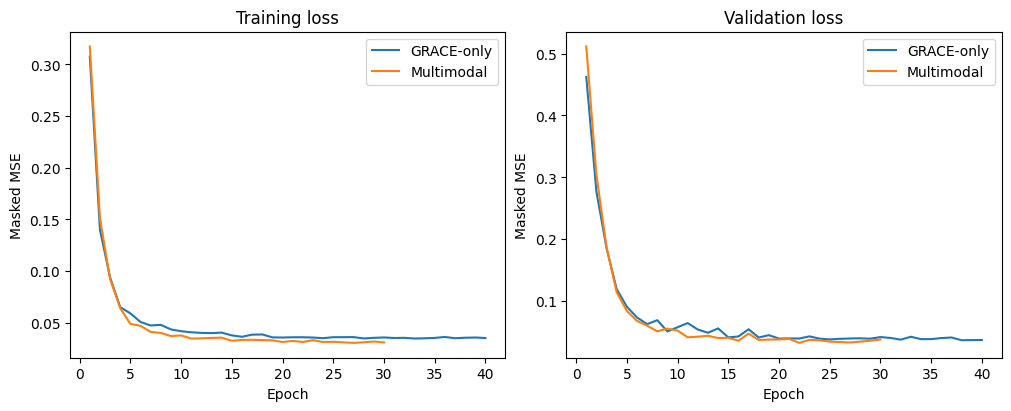

In [26]:
# Run only after setting RUN_TRAINING=True.
if RUN_TRAINING:
    standard_normalization = {'mean': feature_mean.tolist(), 'std': feature_std.tolist(), 'spatial_mask': 'training_mask'}
    grace_model, grace_history = fit_experiment('grace_only', [0], normalization=standard_normalization)
    multimodal_model, multimodal_history = fit_experiment('multimodal', [0, 1, 2], normalization=standard_normalization)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    for label, history in [('GRACE-only', grace_history), ('Multimodal', multimodal_history)]:
        axes[0].plot(history.epoch, history.train_loss, label=label); axes[1].plot(history.epoch, history.validation_loss, label=label)
    axes[0].set(xlabel='Epoch', ylabel='Masked MSE', title='Training loss'); axes[1].set(xlabel='Epoch', ylabel='Masked MSE', title='Validation loss')
    for axis in axes: axis.legend()
    fig.savefig(ARTIFACT_DIRS['figures'] / 'training_validation_loss.png', dpi=160, bbox_inches='tight')
else:
    print('Training disabled. Review the dataset and set RUN_TRAINING=True when ready.')

## 9. Test Evaluation and Matched Persistence Baseline

Metrics are temporal per-cell MAE/RMSE/Pearson correlation, then cosine-latitude weighted across cells, consistent with the repository's evaluation style. The common mask is `training_mask ∩ finite target ∩ finite prediction`; this is checked per target month.

In [12]:
def predict_maps(model, channel_indices, indices, prediction_origins=origins, features_data=None, target_data=None, valid_data=None, tws_mean=None, tws_std=None):
    features_data = normalized_features if features_data is None else features_data
    target_data = normalized_target if target_data is None else target_data
    valid_data = valid_target if valid_data is None else valid_data
    tws_mean = feature_mean[0] if tws_mean is None else tws_mean; tws_std = feature_std[0] if tws_std is None else tws_std
    loader = DataLoader(PatchDataset(features_data[:, channel_indices], target_data, valid_data, indices, prediction_origins), BATCH_SIZE)
    summed = np.zeros((len(indices), ds.sizes['lat'], ds.sizes['lon']), np.float32); count = np.zeros_like(summed)
    lookup = {value: position for position, value in enumerate(indices)}; model.eval()
    with torch.no_grad():
        for sequence, _, _, index, top, left in loader:
            output = model(sequence.to(DEVICE)).cpu().numpy()[:, 0]
            for prediction, month, row, col in zip(output, index.numpy(), top.numpy(), left.numpy()):
                position = lookup[month]; summed[position, row:row+PATCH_SIZE, col:col+PATCH_SIZE] += prediction; count[position, row:row+PATCH_SIZE, col:col+PATCH_SIZE] += 1
    normalized = np.divide(summed, count, out=np.full_like(summed, np.nan), where=count > 0)
    return normalized * tws_std + tws_mean, count > 0

def metrics(prediction, target, valid):
    valid = valid & np.isfinite(prediction) & np.isfinite(target); count = valid.sum(0); enough = count >= 12
    weights = np.broadcast_to(np.cos(np.deg2rad(ds.lat.values))[:, None], enough.shape)
    def weighted(values):
        usable = enough & np.isfinite(values)
        if not usable.any(): return float('nan')
        return float((values[usable] * weights[usable]).sum() / weights[usable].sum())
    error = np.where(valid, prediction - target, 0.0)
    mae = np.divide(np.abs(error).sum(0), count, out=np.full(count.shape, np.nan), where=count > 0)
    rmse = np.sqrt(np.divide((error**2).sum(0), count, out=np.full(count.shape, np.nan), where=count > 0))
    actual, forecast = np.where(valid, target, 0.0), np.where(valid, prediction, 0.0)
    actual_mean = np.divide(actual.sum(0), count, out=np.zeros(count.shape), where=count > 0); forecast_mean = np.divide(forecast.sum(0), count, out=np.zeros(count.shape), where=count > 0)
    a, p = np.where(valid, actual - actual_mean, 0.0), np.where(valid, forecast - forecast_mean, 0.0)
    correlation = np.divide((a*p).sum(0), np.sqrt((a*a).sum(0) * (p*p).sum(0)), out=np.full(count.shape, np.nan), where=count > 1)
    return {'MAE_cm': weighted(mae), 'RMSE_cm': weighted(rmse), 'Pearson_r_area_weighted': weighted(correlation), 'evaluated_months': int(valid.any((1,2)).sum()), 'evaluated_cells': int(enough.sum()), 'valid_cell_months': int(valid.sum())}

if RUN_TRAINING:
    predictions, coverage_by_model = {}, {}
    for name, model, channels in [('grace_only', grace_model, [0]), ('multimodal', multimodal_model, [0,1,2])]:
        predictions[name], coverage_by_model[name] = predict_maps(model, channels, split_indices['test'])
    predictions['persistence'] = target_tws[split_indices['test'] - 1]
    predictions['seasonal_persistence'] = target_tws[split_indices['test'] - 12]
    target = target_tws[split_indices['test']]
    common_valid = valid_target[split_indices['test']] & coverage_by_model['grace_only'] & coverage_by_model['multimodal']
    for prediction in predictions.values(): common_valid &= np.isfinite(prediction)
    if not common_valid.any(): raise RuntimeError('No common valid observations for matched evaluation.')
    results = {name: metrics(prediction, target, common_valid) for name, prediction in predictions.items()}
    for name, prediction in predictions.items():
        xr.Dataset({'prediction': (('time','lat','lon'), prediction), 'target': (('time','lat','lon'), target), 'valid': (('time','lat','lon'), common_valid)}, coords={'time': times[split_indices['test']], 'lat': ds.lat, 'lon': ds.lon}).to_netcdf(ARTIFACT_DIRS['predictions'] / f'{name}_test_predictions.nc')
    run_summary = {'evaluated_dates': [str(date.date()) for date in times[split_indices['test']]], 'common_valid_cell_months': int(common_valid.sum()), 'common_evaluated_cells': int(common_valid.any(0).sum()), 'patch_covered_training_cells': int((coverage_by_model['multimodal'].all(0) & training_mask).sum())}
    (ARTIFACT_DIRS['logs'] / 'test_run_summary.json').write_text(json.dumps(run_summary, indent=2))
    metric_frame = pd.DataFrame(results).T; metric_frame.to_csv(ARTIFACT_DIRS['metrics'] / 'test_metrics.csv'); display(metric_frame)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
    for axis, column in zip(axes, ['MAE_cm', 'RMSE_cm', 'Pearson_r_area_weighted']):
        metric_frame[column].plot.bar(ax=axis, title=column.replace('_', ' ')); axis.tick_params(axis='x', rotation=35)
    fig.savefig(ARTIFACT_DIRS['figures'] / 'grace_only_multimodal_metric_comparison.png', dpi=160, bbox_inches='tight')

## 10. Geographic Generalization

This optional experiment is honestly labeled a **spatial holdout forecast**: training patches touching a conservative 13-cell buffer around Northwest India are excluded, but the region's historical TWSA remains visible at inference because the standard model input includes TWS. It is not a strict unseen-input-region claim.

Held-out cells: 320 eligible training-region cells: 44585 training patches after buffer: 95
geographic_holdout_multimodal | epoch 01/40 | train=0.37790 | validation=0.57541
geographic_holdout_multimodal | epoch 02/40 | train=0.17943 | validation=0.31448
geographic_holdout_multimodal | epoch 03/40 | train=0.10134 | validation=0.20447
geographic_holdout_multimodal | epoch 04/40 | train=0.07641 | validation=0.14098
geographic_holdout_multimodal | epoch 05/40 | train=0.05903 | validation=0.09688
geographic_holdout_multimodal | epoch 06/40 | train=0.05061 | validation=0.07867
geographic_holdout_multimodal | epoch 07/40 | train=0.04677 | validation=0.07016
geographic_holdout_multimodal | epoch 08/40 | train=0.04398 | validation=0.05913
geographic_holdout_multimodal | epoch 09/40 | train=0.03961 | validation=0.05963
geographic_holdout_multimodal | epoch 10/40 | train=0.04088 | validation=0.05414
geographic_holdout_multimodal | epoch 11/40 | train=0.03775 | validation=0.04577
geographic_holdou

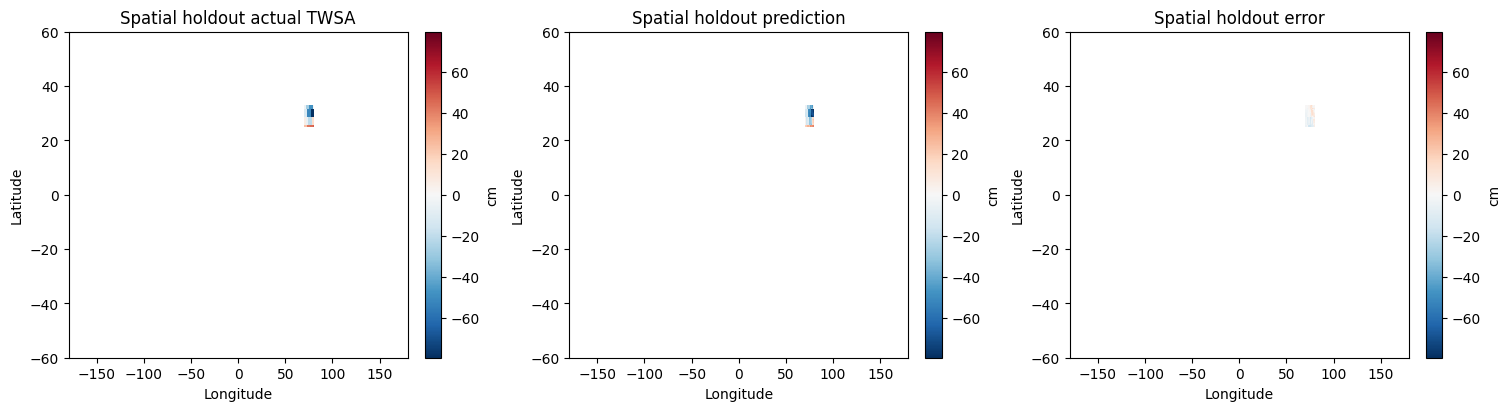

In [16]:
def region_mask(lat_bounds=(25, 33), lon_bounds=(70, 80)):
    return ((ds.lat.values[:, None] >= lat_bounds[0]) & (ds.lat.values[:, None] <= lat_bounds[1]) & (ds.lon.values[None, :] >= lon_bounds[0]) & (ds.lon.values[None, :] <= lon_bounds[1]))
def dilate(mask, radius=HISTORY_MONTHS + 1):
    kernel = 2 * radius + 1
    return torch.nn.functional.max_pool2d(torch.tensor(mask, dtype=torch.float32)[None, None], kernel, stride=1, padding=radius)[0,0].bool().numpy()

holdout = region_mask(); buffered_holdout = dilate(holdout)
holdout_origins = patch_origins(training_mask & holdout)
outside_origins = patch_origins(training_mask, excluded=buffered_holdout)
holdout_training_mask = training_mask & ~buffered_holdout
geo_features, geo_mean, geo_std = normalize(all_features, train_month_indices, holdout_training_mask)
geo_target = (target_tws - geo_mean[0]) / geo_std[0]
print('Held-out cells:', int((training_mask & holdout).sum()), 'eligible training-region cells:', int(holdout_training_mask.sum()), 'training patches after buffer:', len(outside_origins))
RUN_GEOGRAPHIC_HOLDOUT = True
if RUN_GEOGRAPHIC_HOLDOUT:
    geo_normalization = {'mean': geo_mean.tolist(), 'std': geo_std.tolist(), 'spatial_mask': 'training_mask outside buffered held-out region'}
    holdout_model, holdout_history = fit_experiment('geographic_holdout_multimodal', [0,1,2], outside_origins, outside_origins, geo_features, geo_target, valid_target, geo_normalization)
    holdout_prediction, coverage = predict_maps(holdout_model, [0,1,2], split_indices['test'], holdout_origins, geo_features, geo_target, valid_target, geo_mean[0], geo_std[0])
    holdout_valid = valid_target[split_indices['test']] & holdout[None] & coverage
    holdout_result = metrics(holdout_prediction, target_tws[split_indices['test']], holdout_valid)
    holdout_target = target_tws[split_indices['test']]
    xr.Dataset({'prediction': (('time','lat','lon'), holdout_prediction), 'target': (('time','lat','lon'), holdout_target), 'valid': (('time','lat','lon'), holdout_valid), 'holdout_region': (('lat','lon'), holdout)}, coords={'time': times[split_indices['test']], 'lat': ds.lat, 'lon': ds.lon}).to_netcdf(ARTIFACT_DIRS['predictions'] / 'geographic_holdout_predictions.nc')
    pd.DataFrame([holdout_result], index=['multimodal_spatial_holdout_history_visible']).to_csv(ARTIFACT_DIRS['metrics'] / 'geographic_holdout_metrics.csv')
    map_index = -1; actual = np.where(holdout_valid[map_index], holdout_target[map_index], np.nan); predicted = np.where(holdout_valid[map_index], holdout_prediction[map_index], np.nan)
    limit = float(np.nanpercentile(np.abs(np.r_[actual.ravel(), predicted.ravel()]), 98))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for axis, values, title in [(axes[0], actual, 'Spatial holdout actual TWSA'), (axes[1], predicted, 'Spatial holdout prediction'), (axes[2], predicted-actual, 'Spatial holdout error')]:
        image = axis.pcolormesh(ds.lon, ds.lat, values, cmap='RdBu_r', vmin=-limit, vmax=limit); axis.set(title=title, xlabel='Longitude', ylabel='Latitude'); fig.colorbar(image, ax=axis, label='cm')
    fig.savefig(ARTIFACT_DIRS['figures'] / 'geographic_holdout_maps.png', dpi=160, bbox_inches='tight')
    print(holdout_result)
# This excludes every training and validation patch intersecting the buffered region. Held-out history remains visible only at inference.

## 11. Spatial Visualizations, Artifacts, and Reproducibility

Run after the evaluation cell. Maps use a shared TWSA color range for actual/predicted data, and label their true patch or geographic extent. All figures and metrics are written under the verified `OUTPUT_DIR`.

Final artifacts are saved only under: /content/drive/Shareddrives/DATA 255 Group/255 Group/Group Project/Final/ConvLSTM
For notebook persistence, use Colab File > Save a copy in Drive and select the verified ConvLSTM folder.


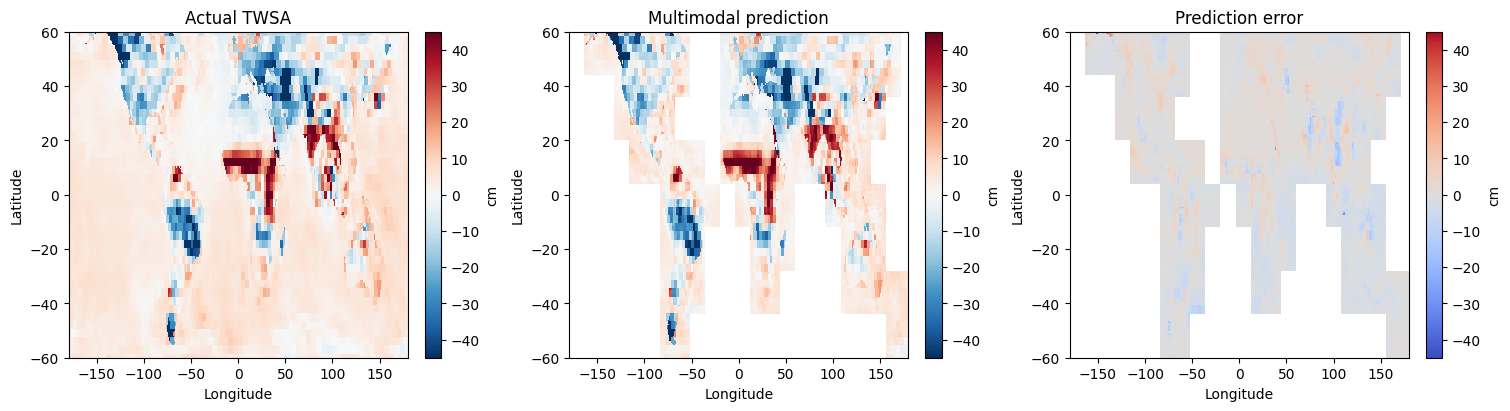

In [29]:
if RUN_TRAINING:
    # Example uses the final available test month and the multimodal result loaded in the evaluation loop.
    saved = xr.open_dataset(ARTIFACT_DIRS['predictions'] / 'multimodal_test_predictions.nc')
    actual, predicted = saved.target.isel(time=-1), saved.prediction.isel(time=-1)
    limit = float(np.nanpercentile(np.abs(np.r_[actual.values.ravel(), predicted.values.ravel()]), 98))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for axis, values, title, cmap, vmin, vmax in [(axes[0], actual, 'Actual TWSA', 'RdBu_r', -limit, limit), (axes[1], predicted, 'Multimodal prediction', 'RdBu_r', -limit, limit), (axes[2], predicted-actual, 'Prediction error', 'coolwarm', -limit, limit)]:
        image = axis.pcolormesh(ds.lon, ds.lat, values, cmap=cmap, vmin=vmin, vmax=vmax); axis.set(title=title, xlabel='Longitude', ylabel='Latitude'); fig.colorbar(image, ax=axis, label='cm')
    fig.savefig(ARTIFACT_DIRS['figures'] / 'test_map_comparison.png', dpi=160, bbox_inches='tight')
    saved.close()

print('Final artifacts are saved only under:', OUTPUT_DIR)
print('For notebook persistence, use Colab File > Save a copy in Drive and select the verified ConvLSTM folder.')